# Self-paced learning with loss feedback

Instead of a fixed difficulty, the curriculum can follow the **training losses** of items : a `LossTracker` records
the loss of each item when it is seen, and gives its difficulty to the `Curriculum`. Items with low losses are
sampled first, and harder items are introduced as the competence grows (self-paced learning).

We train a minimal waveform auto-encoder on sounds of different complexity, with a manual training loop, then with
PyTorch Lightning and `CurriculumCallback`.

In [1]:
import math, tempfile, collections
from pathlib import Path
import numpy as np
import soundfile as sf
import torch, torch.nn as nn
import matplotlib.pyplot as plt
from acids_dataset.datasets import AudioDataset
from acids_dataset.sampling import Curriculum, LossTracker

SR = 16000
torch.manual_seed(0); np.random.seed(0)
root = Path(tempfile.mkdtemp()) / "complexity"
root.mkdir()
t = torch.arange(2 * SR) / SR

generators = {
    "sine": lambda: torch.sin(2 * math.pi * np.random.uniform(100, 300) * t),
    "chord": lambda: sum(torch.sin(2 * math.pi * f * t) for f in np.random.uniform(100, 1000, 3)),
    "harmonic": lambda: sum(torch.sin(2 * math.pi * np.random.uniform(100, 300) * k * t) / k for k in range(1, 12)),
    "noise": lambda: torch.randn(len(t)),
}
for name, generate in generators.items():
    for i in range(6):
        x = generate()
        sf.write(root / f"{name}_{i}.wav", (0.4 * x / x.abs().max()).numpy(), SR)

dataset = AudioDataset(root, sr=SR, chunk_length=4096, meta_regexp=["**/{{kind}}_*.wav"], output_pattern="{waveform,index}")
kinds = dataset.item_labels("kind")
names = sorted(generators)
print(len(dataset), "items :", collections.Counter(kinds))

192 items : Counter({'chord': 48, 'harmonic': 48, 'noise': 48, 'sine': 48})


## A minimal auto-encoder

Two strided convolutions down to 8 channels at 1/16 of the sample rate, and two transposed convolutions back. Item
losses are needed by the tracker : the loss is computed per item (`reduction="none"`), and averaged for the update.

In [2]:
class TinyAutoEncoder(nn.Module):
    def __init__(self, channels=16, latent=8):
        super().__init__()
        self.encoder = nn.Sequential(nn.Conv1d(1, channels, 9, stride=4, padding=4), nn.GELU(),
                                     nn.Conv1d(channels, latent, 9, stride=4, padding=4))
        self.decoder = nn.Sequential(nn.ConvTranspose1d(latent, channels, 8, stride=4, padding=2), nn.GELU(),
                                     nn.ConvTranspose1d(channels, 1, 8, stride=4, padding=2))

    def forward(self, x):
        return self.decoder(self.encoder(x))

    def item_losses(self, x):
        """one loss per item : relative squared error."""
        return (self(x) - x).pow(2).mean((-1, -2)) / x.pow(2).mean((-1, -2)).clamp(min=1e-6)

## Manual training loop

The tracker records losses with an exponential moving average (`strategy="ema"`). With `groups` (here, the file of
each item), items that were never seen get the mean loss of their group. Before any loss is recorded, all items have
the same (unknown) difficulty, and are sampled uniformly.

In [3]:
def run(curriculum_on, n_epochs=12, seed=0):
    torch.manual_seed(seed)
    model = TinyAutoEncoder()
    optimizer = torch.optim.Adam(model.parameters(), lr=3e-3)
    tracker = LossTracker(len(dataset), strategy="ema", momentum=0.5, groups=dataset.item_labels("original_path"))
    curriculum = Curriculum(tracker, start=0.3, end=1., length=8) if curriculum_on else None
    loader = dataset.get_loader(batch_size=16, curriculum=curriculum, seed=seed, max_samples=256)
    sampled, competences, group_losses = [], [], []
    for epoch in range(n_epochs):
        loader.sampler.set_epoch(epoch)
        counts = collections.Counter()
        for batch in loader:
            losses = model.item_losses(batch["waveform"])
            optimizer.zero_grad(); losses.mean().backward(); optimizer.step()
            tracker.update(batch["index"], losses.detach())
            counts.update(kinds[i] for i in batch["index"].tolist())
        sampled.append([counts[k] / sum(counts.values()) for k in names])
        competences.append(curriculum.competence if curriculum else 1.)
        difficulty = tracker.difficulty()
        group_losses.append([difficulty[[i for i, k in enumerate(kinds) if k == name]].mean().item() for name in names])
    return np.array(sampled), competences, np.array(group_losses), tracker

uniform = run(False)
self_paced = run(True)

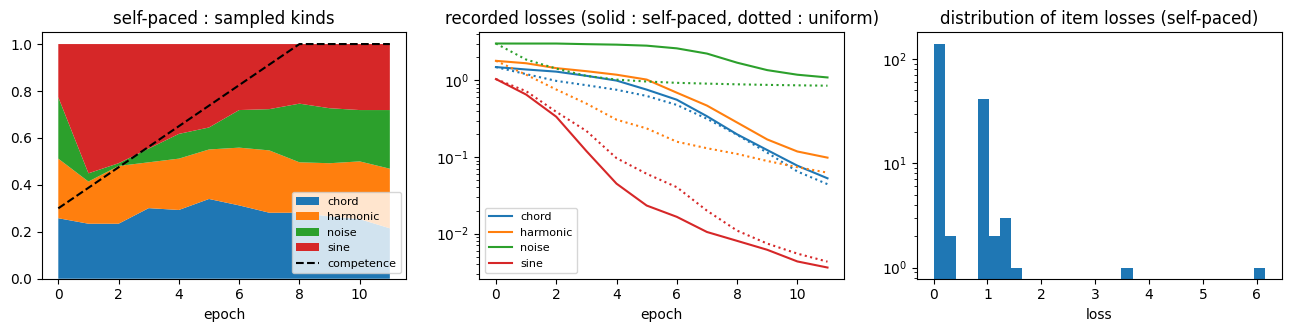

{'n_seen': 192, 'ratio_seen': 1.0, 'mean': 0.3126, 'std': 0.6226}


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.2))
axes[0].stackplot(range(len(self_paced[0])), self_paced[0].T, labels=names)
axes[0].plot(self_paced[1], "k--", label="competence"); axes[0].set_title("self-paced : sampled kinds")
axes[0].set_xlabel("epoch"); axes[0].legend(loc="lower right", fontsize=8)
for k, name in enumerate(names):
    axes[1].plot(self_paced[2][:, k], color="C%d" % k, label=name)
    axes[1].plot(uniform[2][:, k], color="C%d" % k, ls=":")
axes[1].set_yscale("log"); axes[1].set_title("recorded losses (solid : self-paced, dotted : uniform)"); axes[1].set_xlabel("epoch")
axes[1].legend(fontsize=8)
stats = self_paced[3].statistics()
axes[2].hist(self_paced[3].values[self_paced[3].seen].numpy(), bins=30, log=True)
axes[2].set_title("distribution of item losses (self-paced)"); axes[2].set_xlabel("loss")
plt.show()
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in stats.items() if k in ["n_seen", "ratio_seen", "mean", "std"]})

At the first epoch, no loss is recorded yet, and items are sampled uniformly. Pure sines are then reconstructed
first and get the lowest losses : the self-paced curriculum samples them more, and holds back noise (the hardest
kind, that a small convolutional auto-encoder cannot compress) until the competence reaches 1. As losses are updated
during training, items that become easy are re-ranked : the curriculum adapts to the model.

The price is visible on the noise losses : at the same number of steps, uniform sampling has trained more on noise.
Self-paced learning is useful when hard items are noisy, or harmful early in training, rather than to learn
everything faster.

## With PyTorch Lightning

`CurriculumCallback` does the bookkeeping : it gives epochs (and steps) to the curriculum, records the item losses
returned by `training_step` (with the `index` entry of batches, gathered over processes in distributed training),
logs the competence and the mean loss, and saves the curriculum and the tracker in checkpoints.

In [5]:
try:
    import lightning.pytorch as pl
except ImportError:
    import pytorch_lightning as pl
from acids_dataset.lightning import CurriculumCallback

class LitAutoEncoder(pl.LightningModule):
    def __init__(self):
        super().__init__()
        self.model = TinyAutoEncoder()

    def training_step(self, batch, batch_idx):
        losses = self.model.item_losses(batch["waveform"])
        return {"loss": losses.mean(), "item_losses": losses.detach()}

    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters(), lr=3e-3)

tracker = LossTracker(len(dataset), groups=dataset.item_labels("original_path"))
curriculum = Curriculum(tracker, start=0.3, end=1., length=6)
loader = dataset.get_loader(batch_size=16, curriculum=curriculum, seed=0, max_samples=256)
trainer = pl.Trainer(max_epochs=8, accelerator="cpu", logger=pl.loggers.CSVLogger(tempfile.mkdtemp()),
                     enable_checkpointing=False, enable_progress_bar=False, enable_model_summary=False,
                     callbacks=[CurriculumCallback(curriculum, tracker)])
trainer.fit(LitAutoEncoder(), loader)

print("competence at the end :", curriculum.competence)
print("items seen            :", tracker.statistics()["n_seen"], "/", len(dataset))
print("logged metrics        :", {k: round(float(v), 4) for k, v in trainer.logged_metrics.items()})

GPU available: True (mps), used: False
TPU available: False, using: 0 TPU cores
/Users/domkirke/miniconda3/envs/acidsdataset/lib/python3.10/site-packages/pytorch_lightning/trainer/setup.py:175: GPU available but not used. You can set it by doing `Trainer(accelerator='gpu')`.
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/Users/domkirke/miniconda3/envs/acidsdataset/lib/python3.10/site-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/domkirke/miniconda3/envs/acidsdataset/lib/python3.10/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers

competence at the end : 1.0
items seen            : 192 / 192
logged metrics        : {'curriculum/competence': 1.0, 'curriculum/mean_loss': 1.3889, 'curriculum/ratio_seen': 1.0}


The state of the curriculum and of the tracker is saved in checkpoints by the callback, and can also be saved by hand :

In [6]:
state = curriculum.state_dict()
restored = Curriculum(LossTracker(len(dataset)), start=0.3, end=1., length=6)
restored.load_state_dict(state)
print(restored.current_epoch, torch.allclose(restored.difficulty.values, tracker.values))

7 True
